CSE 6040 Extra Credit Assignment

## Cat Breed & Characteristics Study
My fiancé and I moved in together recently and are planning on adopting a cat around the end of May. However, due to our busy schedules, we want to be mindful of the amount of shedding we'll need to clean up daily. While we love all types of feline creatures, we want to find a breed that sheds less and fits well with our lifestyle. To better guide our adoption decision, I am using a cat breeds dataset that I found on Kaggle (https://www.kaggle.com/datasets/warcoder/cat-breeds-details), which includes ratings across 15 lifestyle and health traits for 62 breeds. 

**Research Question: Which cat breeds shed the least, and do those breeds also score well on other lifestyle traits?**

Using this dataset, I will explore shedding levels across different cat breeds and identify the characteristics associated with those breeds. This analysis will hopefully help us make a better informed decision when we visit the shelters :)   

### Setup
Let's load some packages to get us started.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Loading the dataset

In [2]:
df = pd.read_csv('cat_breeds.csv')
df.head()

,name,length,origin,min_life_expectancy,max_life_expectancy,min_weight,max_weight,family_friendly,shedding,general_health,playfulness,children_friendly,grooming,intelligence,other_pets_friendly
0,Abyssinian,12 to 16 inches,Southeast Asia,9.0,15.0,6.0,10.0,3,3,2,5,5,3,5,5
1,Aegean,Medium,Greece,9.0,10.0,7.0,10.0,5,3,4,4,5,4,4,3
2,American Bobtail,Medium,United States and Canada,11.0,15.0,8.0,13.0,4,4,4,4,4,3,4,4
3,American Shorthair,12 to 15 inches,United States,15.0,20.0,7.0,12.0,3,3,4,2,4,4,4,3
4,American Wirehair,Medium to large,United States,14.0,18.0,8.0,15.0,4,3,5,3,4,5,4,3


### Cleaning the data and overview

In [3]:
# Checking the rows and columns
print(f"\nDataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
print("\nColumn names and data types:")
print(df.dtypes)


Dataset shape: 62 rows × 15 columns

Column names and data types:
name                    object
length                  object
origin                  object
min_life_expectancy    float64
max_life_expectancy    float64
min_weight             float64
max_weight             float64
family_friendly          int64
shedding                 int64
general_health           int64
playfulness              int64
children_friendly        int64
grooming                 int64
intelligence             int64
other_pets_friendly      int64
dtype: object


In [4]:
# Checking if there are any missing values
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
name                   0
length                 0
origin                 0
min_life_expectancy    0
max_life_expectancy    0
min_weight             0
max_weight             0
family_friendly        0
shedding               0
general_health         0
playfulness            0
children_friendly      0
grooming               0
intelligence           0
other_pets_friendly    0
dtype: int64


The dataset contains 62 cat breeds across 15 columns, with zero missing values. This means that the data is already clean and ready for analysis with no imputation needed.

All trait columns (such as `shedding`, `grooming`, `family_friendly`, `playfulness`, etc.) are rated on a 1–5 integer scale, making them straightforward to compare and visualize. The key column for this analysis is `shedding`, which will serve as our primary filter throughout. Supporting columns will help us evaluate whether low-shedding breeds are also good lifestyle matches for a busy couple.

### Exploratory Data Analysis

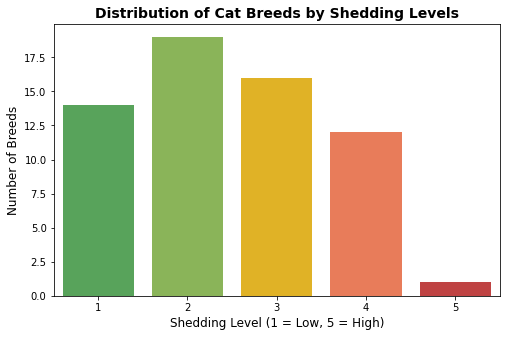

In [5]:
# Exploring shedding levels across all cat breeds
plt.figure(figsize=(8, 5))
palette = ['#4caf50', '#8bc34a', '#ffc107', '#ff7043', '#d32f2f']
sns.countplot(x='shedding', data=df, hue='shedding', palette=palette, legend=False)
plt.title('Distribution of Cat Breeds by Shedding Levels', fontsize=14, fontweight='bold')
plt.xlabel('Shedding Level (1 = Low, 5 = High)', fontsize=12)
plt.ylabel('Number of Breeds', fontsize=12)
plt.show()

The distribution above reveals that the majority of breeds fall within shedding levels 1 and 2, with 14 breeds rated as very low shedding (level 1) and 19 rated as low shedding (level 2). Together, these 33 breeds represent over half of all breeds in the dataset (**53.2%**), which is encouraging. This means low-shedding options are plentiful. Only 1 breed reaches the highest shedding level of 5, suggesting that extreme shedding is quite rare among documented breeds. 

With 33 low-shedding breeds identified, the next step is to see which specific breeds they are. 

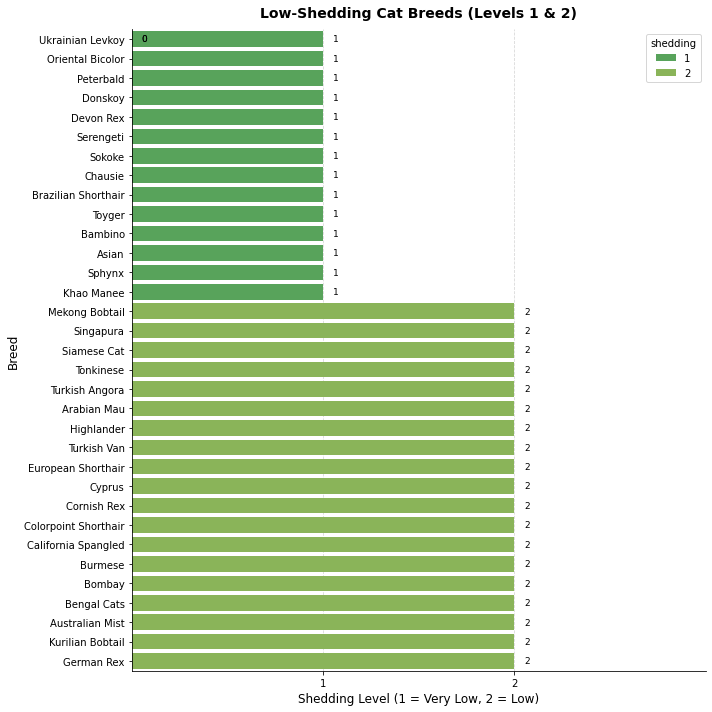

In [6]:
# Sorting breeds by shedding level to identify the lowest‑shedding breeds
low_shedding = df[df['shedding'] <= 2].sort_values('shedding')[['name', 'shedding']]

level_colors = {1: '#4caf50', 2: '#8bc34a'}

plt.figure(figsize=(10, 10))
ax = sns.barplot(y='name', x='shedding', data=low_shedding,
                 hue='shedding', palette=level_colors, legend=True)

# Add value labels to the end of each bar
for bar in ax.patches:
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height() / 2,
            f'{int(bar.get_width())}', va='center', fontsize=9)

# Clean up the frame
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlim(0, 3)
ax.set_xticks([1, 2])
ax.xaxis.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)

plt.title('Low-Shedding Cat Breeds (Levels 1 & 2)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Shedding Level (1 = Very Low, 2 = Low)', fontsize=12)
plt.ylabel('Breed', fontsize=12)
plt.tight_layout()
plt.show()

With the data narrowed to 33 breeds, we can see a clear split between level 1 (very low) and level 2 (low) shedders. Notably, several well-known breeds such as the Siamese, Bengal, and Sphynx appear in this group, which is promising since these breeds are also commonly found in shelters. This chart gives us a concrete visual shortlist to reference during our shelter visits.

However, shedding is only one factor of daily maintenance. My fiancé and I would also like to minimize grooming time. The next section explores whether low-shedding breeds require more or less grooming effort. 

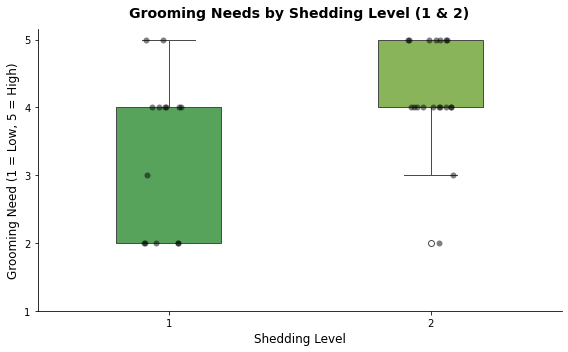

In [7]:
# Exploring whether low shedding is associated with higher grooming requirements.
low_shedding = df[df['shedding'] <= 2].copy()

plt.figure(figsize=(8, 5))
ax = sns.boxplot(x='shedding', y='grooming', data=low_shedding,
                 hue='shedding', palette={1: '#4caf50', 2: '#8bc34a'},
                 width=0.4, legend=False)
sns.stripplot(x='shedding', y='grooming', data=low_shedding,
              color='black', alpha=0.5, size=6, jitter=True)

ax.spines[['top', 'right']].set_visible(False)
ax.set_yticks([1, 2, 3, 4, 5])
plt.title('Grooming Needs by Shedding Level (1 & 2)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Shedding Level', fontsize=12)
plt.ylabel('Grooming Need (1 = Low, 5 = High)', fontsize=12)
plt.tight_layout()
plt.show()

The boxplot above shows us that low shedding does not necessarily mean low maintenance. Level 1 shedders have a wider spread of grooming needs, ranging from 2 to 5, while level 2 shedders are more consistently concentrated around grooming levels 4–5. This makes sense since hairless or curly-coated breeds shed very little but require regular skin cleaning or coat maintenance. For us, grooming effort is just as important a factor as shedding.

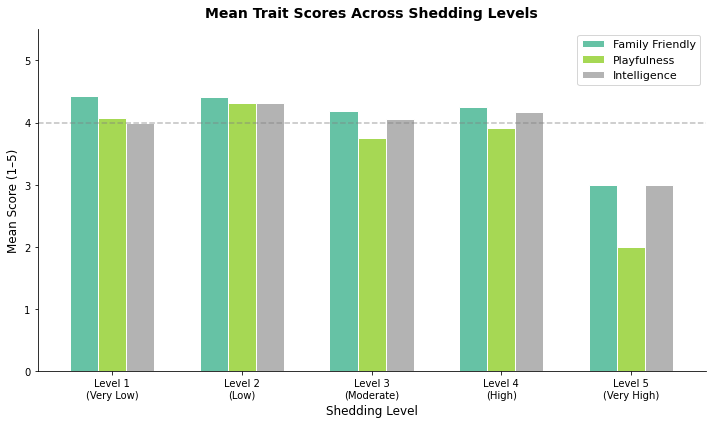

In [8]:
# Exploring mean trait scores across all shedding levels
traits_of_interest = ['family_friendly', 'playfulness', 'intelligence']
shedding_labels = {1: 'Very Low', 2: 'Low', 3: 'Moderate', 4: 'High', 5: 'Very High'}

means = df.groupby('shedding')[traits_of_interest].mean().round(2)
means.index = [f"Level {i}\n({shedding_labels[i]})" for i in means.index]
means.columns = ['Family Friendly', 'Playfulness', 'Intelligence']

ax = means.plot(kind='bar', figsize=(10, 6), colormap='Set2',
                edgecolor='white', width=0.65)
ax.set_title('Mean Trait Scores Across Shedding Levels',
             fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Shedding Level', fontsize=12)
ax.set_ylabel('Mean Score (1–5)', fontsize=12)
ax.set_ylim(0, 5.5)
ax.set_xticklabels(means.index, rotation=0, fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=11)
ax.axhline(y=4, color='gray', linestyle='--', alpha=0.5, label='Score = 4 reference')
plt.tight_layout()
plt.show()

Previous analysis shows that we have plenty of low shedders to choose from. However, it is worth questioning if the low shedding breeds actually make good companions? The chart above compares mean scores for family-friendliness, playfulness, and intelligence across all shedding levels.

Results show that breeds at shedding levels 1 and 2 consistently score at or above **4.0** on all three traits — comparable to, and in some cases higher than, mid-range shedding breeds. This means we are not sacrificing companionship quality by prioritizing low shedding.

It is worth noting that the level 5 group shows a sharp drop across all three traits, but this should be interpreted cautiously since only **one breed** in the entire dataset falls at that level. That single data point is not representative enough to draw broad conclusions about heavy-shedding breeds in general.

Overall, this chart confirms that low-shedding breeds are not just manageable — they tend to be highly social, playful, and intelligent companions.

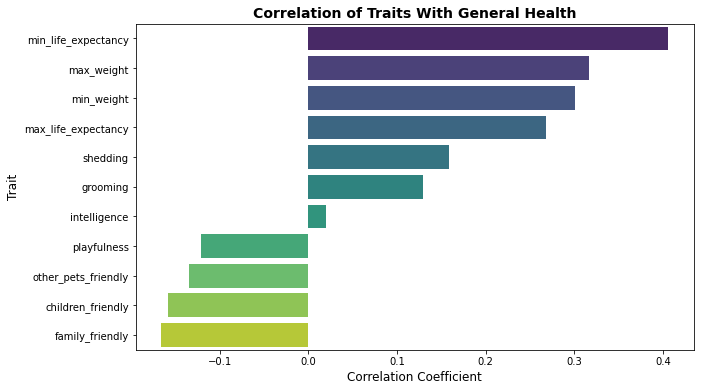

In [9]:
# Exploring the correlation of each trait with general health

# Select only numeric columns
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Compute correlations with general_health
health_corr = numeric_df.corr()['general_health'].sort_values(ascending=False)

# Drop the self-correlation (always 1.0)
health_corr = health_corr.drop('general_health')

# Plot
plt.figure(figsize=(10,6))
sns.barplot(x=health_corr.values, y=health_corr.index, hue=health_corr.index, palette='viridis', legend=False)
plt.title('Correlation of Traits With General Health', fontsize=14, fontweight='bold')
plt.xlabel('Correlation Coefficient', fontsize=12)
plt.ylabel('Trait', fontsize=12)
plt.show()

The plot above shows us that traits ``min_life_expectancy`` and ``max_life_expectancy`` shows very high positive correlation to general health. This makes sense because breeds that tend to be healthier generally live longer and have less inherited medical issues. 

Traits ``min_weight`` and ``max_weight`` also shows positive correlation to general health. This may not necessarily mean that heavier cats are healthier, but some sturdier cats tend to have fewer chronic genetic conditions than skinny cats. 

The positive correlation between general health with ``shedding`` and ``grooming`` are relatively low, which means that the amount of shedding or grooming a cat requires does not depict if it'll be any less healthy. This is good to know because we can prioritize low shedding breeds without worrying it compromises overall health.  

The trait ``intelligence`` shows weak or negligible correlations, hovering near zero. This makes sense since this trait is behavioral so it's expected that it does not strongly predict health. 

Lastly, traits like ``playfulness``, ``other_pets_friendly``, ``children_friendly`` and ``family_friendly`` have weak negative correlations with general health. Although the correlations are weak, some extremely social or docile breeds could have more genetic health concerns. 

In [10]:
# Exploring breeds with both shedding level=1 and grooming need=2
result = df[(df['shedding'] == 1) & (df['grooming'] == 2)]
print(result[['name', 'shedding', 'grooming']])

                name  shedding  grooming
9            Bambino         1         2
25           Donskoy         1         2
41         Peterbald         1         2
54            Sphynx         1         2
60  Ukrainian Levkoy         1         2


In the previous plot, we saw that the positive correlation between shedding and grooming with general health is relatively low. This means that I can proceed with my preferred traits such as low shedding and low grooming needs without worry that it'll negatively affect their health. 

The data above shows that there are 5 breeds with the lowest shedding level and lowest grooming needs. The 5 breeds are Bambino, Donsky, Peterbald, Sphynx and Ukrainian Levkoy. In the next step, we will explore the life expectancy range of these 5 breeds to see how long we might expect to share our home with them. 

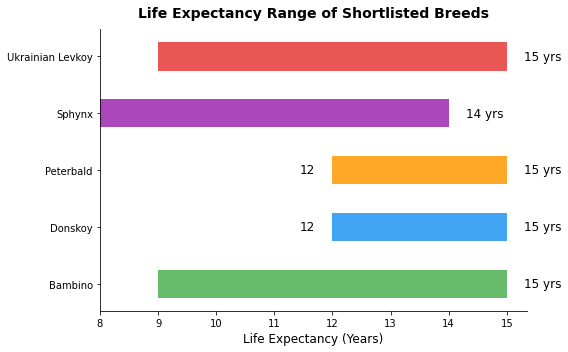

In [11]:
# Life expectancy range for the 5 shortlisted breeds
target_breeds = df[(df['shedding'] == 1) & (df['grooming'] == 2)].copy().reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#4caf50', '#2196f3', '#ff9800', '#9c27b0', '#e53935']

for i, (_, row) in enumerate(target_breeds.iterrows()):
    ax.barh(row['name'], row['max_life_expectancy'] - row['min_life_expectancy'],
            left=row['min_life_expectancy'], color=colors[i], height=0.5, alpha=0.85)

    # Only show min label if it won't collide with the breed name (i.e. bar starts after x=10)
    if row['min_life_expectancy'] > 10:
        ax.text(row['min_life_expectancy'] - 0.3, i,
                f"{int(row['min_life_expectancy'])}",
                va='center', ha='right', fontsize=12)

    ax.text(row['max_life_expectancy'] + 0.3, i,
            f"{int(row['max_life_expectancy'])} yrs",
            va='center', ha='left', fontsize=12)

ax.spines[['top', 'right']].set_visible(False)
ax.set_xlabel('Life Expectancy (Years)', fontsize=12)
ax.set_title('Life Expectancy Range of Shortlisted Breeds',
             fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

All five shortlisted breeds offer a solid lifespan, generally ranging from **9 to 15 years** depending on the breed. Out of all five breeds, **Donskoy and Peterbald** have the highest minimum life expectancy at **12 years**, making them the most consistently long-lived of the five. Since we are planning on a long-term commitment, this is very desirable for us.

The **Bambino, Sphynx, and Ukrainian Levkoy** can live up to **14 or 15 years** at the high end, but their ranges start at 8 or 9, meaning some individuals may have shorter lifespans.

Life expectancy is worth factoring into an adoption decision, not just emotionally, but practically, since longer-lived breeds will require sustained veterinary care and attention over many years. With that in mind, the final table below brings together all the traits side by side for a complete comparison.

In [ ]:
# Complete comparison of all traits for the 5 shortlisted breeds 
target_breeds = df[(df['shedding'] == 1) & (df['grooming'] == 2)].copy()

display_cols = {
    'name': 'Breed', 'shedding': 'Shedding', 'grooming': 'Grooming',
    'family_friendly': 'Family Friendly', 'playfulness': 'Playfulness',
    'intelligence': 'Intelligence', 'children_friendly': 'Children Friendly',
    'other_pets_friendly': 'Other Pets Friendly', 'general_health': 'General Health',
    'min_life_expectancy': 'Min Life Exp.', 'max_life_expectancy': 'Max Life Exp.'
}

summary = target_breeds[display_cols.keys()].rename(columns=display_cols).reset_index(drop=True)
summary.index += 1  # Start index at 1 instead of 0

summary.style \
    .background_gradient(cmap='RdYlGn', subset=['Family Friendly', 'Playfulness',
                                                  'Intelligence', 'Children Friendly',
                                                  'Other Pets Friendly', 'General Health'],
                          vmin=1, vmax=5) \
    .set_properties(**{'text-align': 'center', 'font-size': '11px'}) \
    .set_properties(subset=['Breed'], **{'text-align': 'left', 'font-weight': 'bold'}) \
    .format(precision=0) \
    .set_caption("Characteristics of Breeds with Level 1 Shedding and Level 2 Grooming Needs") \
    .set_table_styles([
        {'selector': 'caption', 'props': [('font-size', '14px'),
                                           ('font-weight', 'bold'), ('padding', '10px')]},
        {'selector': 'th', 'props': [('background-color', '#404040'),
                                      ('color', 'white'), ('font-size', '11px'),
                                      ('text-align', 'center'), ('padding', '6px')]},
        {'selector': 'td', 'props': [('padding', '6px')]},
    ])

The table above brings everything together. There are a few patterns stand out across the five finalists:

- **Family-friendliness and children-friendliness** are consistently high (4–5) across all five breeds, confirming these are well-suited companion animals for a home environment.
- **Playfulness and intelligence** scores are strong across the board, meaning these breeds will be engaging and especially fun to live with.
- **General health** scores show some variation, with certain breeds scoring lower. This is worth noting when budgeting for veterinary care, as some of these hairless or semi-hairless breeds can be more prone to specific genetic conditions.
- **Other-pets-friendliness** is moderate to high for all five, which is useful to know if we ever consider adding another pet to the household in the future (which will most likely be another cat).

Taking everything into consideration (shedding, grooming, lifestyle traits, and life expectancy), the **Sphynx and Ukranian Levkoy** emerge as the most well-rounded choices, scoring strongly across nearly every dimension we care about.

### Conclusion and Next Steps
Overall, this analysis explored shedding levels across cat breeds to help identify low‑shedding options that fit well with our busy schedule. Based on the dataset, we came to the conclusion that the breeds with the lowest shedding levels and lowest grooming needs are **Bambino, Donsky, Peterbald, Sphynx and Ukranian Levkoy**. All five breeds met the core criteria:
- Shedding level = 1 (very low — minimal daily fur cleanup)
- Grooming need = 2 (low — minimal brushing or coat maintenance)
- Strong scores on family-friendliness, playfulness, and intelligence
- Life expectancies ranging from 8 to 14+ years

The broader analysis also delivered a key reassurance: the health correlation data confirmed that selecting for low shedding and grooming does not compromise a breed's overall health. And the trait comparison across shedding levels showed that low-shedding breeds are just as playful and family-friendly as any other group.

Now that I have done a thorough analysis of each cat breed and their characteristics, we will prioritize these five breeds or mixed-breed cats with similar physical and behavioral characteristics when we visit the shelters. Even if an exact breed match is unavailable, the traits identified in this analysis give us a clear, data-driven profile to look for. We are excited for the next chapter! 🐾🐱🐈‍⬛ 🐈